# ResonantBERT v2 — CNN Evaluation & Comparison with Baselines

Evaluates **ResonantBERT v2 + RankingTower v2** (checkpoints in `./model`) on the CNN Track A test split
and compares it with the 5 baselines (Random, Rule-Based, TF-IDF + Ridge, Sentence-BERT, LLM Zero-Shot).

**Run the baseline notebook first** (`ResonantBERTv2_LOCAL_Evaluation (1).ipynb`). This notebook reads its outputs
from `eval_results/cnn/`:
- `cnn_split.json`: test ids and the exact ranked test lists
- `test_scores_cnn_baselines.csv`: every baseline's score for every test article

All methods are re-scored here with **one** metric implementation on the **same** groups, so every
comparison is paired.

**Methods from our model**
- `ResonantBERT v2`: encoder → 128-d viral embedding → RankingTower v2 (the full system)
- `ResonantBERT v2 (no tower)`: the encoder's own `concept_score` head (ablation)

ResonantBERT was trained on BBC ranking groups; CNN is a **zero-shot, cross-publisher** evaluation.

**Needs:** `torch` (CUDA 12.8+ build for RTX 50xx), `transformers`, `peft`, `scipy`, `pandas`, `matplotlib`.

In [11]:
# ============================================================
# SETUP
# ============================================================
import torch, types

# transformers 5.x imports a symbol newer torch removed (same patch as training)
if not hasattr(torch, "_utils"):
    torch._utils = types.ModuleType("torch._utils")
if not hasattr(torch._utils, "_get_device_index"):
    def _get_device_index(device, optional=False, allow_cpu=False):
        if device is None:
            if optional: return None
            raise ValueError("device is None")
        if isinstance(device, str): device = torch.device(device)
        if isinstance(device, torch.device):
            if device.type == "cpu":
                if allow_cpu: return -1
                raise RuntimeError("CPU not allowed")
            return device.index if device.index is not None else 0
        return device
    torch._utils._get_device_index = _get_device_index

import os, re, json, glob, random, warnings
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import kendalltau, spearmanr, ttest_rel, wilcoxon
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings('ignore')

REPO_DIR       = os.path.abspath(".")
CHECKPOINT_DIR = os.path.join(REPO_DIR, "model")
CNN_CSV        = os.path.join(REPO_DIR, "cnn_mass_dataset", "cnn_labels_with_content.csv")
BASELINE_DIR   = os.path.join(REPO_DIR, "eval_results", "cnn")
OUTPUT_DIR     = os.path.join(REPO_DIR, "eval_results", "cnn_sota")
FIG_DIR        = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

NEWS_VALUES = ["timeliness", "proximity", "impact", "prominence", "conflict", "novelty", "human_interest"]

# Must match the training notebook
TOKENIZER_NAME = "answerdotai/ModernBERT-base"
MAX_SEQ_LEN    = 320
EMBEDDING_DIM  = 128
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05

SEED        = 42
SCORE_BATCH = 32        # lower to 16 if you hit CUDA OOM
N_BOOT      = 2000      # bootstrap resamples for confidence intervals

OURS, OURS_ABL = "ResonantBERT v2", "ResonantBERT v2 (no tower)"   # method names in tables/figures

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

Device: cuda (NVIDIA GeForce RTX 5050 Laptop GPU)


In [12]:
# ============================================================
# LOAD TEST SPLIT + BASELINE SCORES (from the baseline notebook)
# ============================================================
split_path  = os.path.join(BASELINE_DIR, "cnn_split.json")
scores_path = os.path.join(BASELINE_DIR, "test_scores_cnn_baselines.csv")
for p in (split_path, scores_path):
    assert os.path.exists(p), f"Missing {p}. Run the baseline notebook first."

with open(split_path, encoding="utf-8") as f:
    split = json.load(f)
TARGET = split["target"]

base_scores = pd.read_csv(scores_path, encoding="utf-8")
BASELINES = [c for c in base_scores.columns if c not in ["id", "section", "gold"] + NEWS_VALUES]
assert base_scores["id"].tolist() == split["test_ids"], "Baseline scores and split are out of sync; re-run the baseline notebook"

# Attach headline/body text to the test articles
cnn = pd.read_csv(CNN_CSV, encoding="utf-8").set_index("id")
test_df = base_scores.copy()
test_df["headline"] = cnn.loc[test_df["id"], "title"].astype(str).values
test_df["body"]     = cnn.loc[test_df["id"], "content"].astype(str).values

id_to_row = {i: r for r, i in enumerate(test_df["id"])}
test_groups = [np.array([id_to_row[i] for i in g]) for g in split["test_groups"]]

print(f"Target: {TARGET} | test articles: {len(test_df)} | test groups: {len(test_groups)}")
print(f"Baselines found: {BASELINES}")

Target: sum | test articles: 1860 | test groups: 201
Baselines found: ['Random', 'Rule-Based', 'TF-IDF + Ridge', 'Sentence-BERT', 'LLM Zero-Shot (Qwen2.5-1.5B-Instruct)']


In [13]:
# ============================================================
# METRICS (identical to the baseline notebook)
# ============================================================
def dcg_at_k(gains, k):
    gains = gains[:k]
    return float((gains / np.log2(np.arange(2, gains.size + 2))).sum())

def ndcg_at_k(pred, gold, k):
    gains = gold - gold.min()
    idcg = dcg_at_k(np.sort(gains)[::-1], k)
    return dcg_at_k(gains[np.argsort(-pred, kind="stable")], k) / idcg if idcg > 0 else 0.0

def kendall_tau_metric(pred, gold):
    tau, _ = kendalltau(pred, gold)
    return float(tau) if not np.isnan(tau) else 0.0

def pairwise_accuracy(pred, gold):
    correct, total = 0.0, 0
    for i in range(len(pred)):
        for j in range(i + 1, len(pred)):
            if gold[i] == gold[j]: continue
            total += 1
            d = (pred[i] - pred[j]) * (gold[i] - gold[j])
            correct += 1.0 if d > 0 else (0.5 if pred[i] == pred[j] else 0.0)
    return correct / max(total, 1)

def metrics_from_scores(scores, method_name):
    gold = test_df["gold"].to_numpy(dtype=float)
    per_group = {}
    for gi, rows in enumerate(test_groups):
        p, g = scores[rows], gold[rows]
        per_group[gi] = {"ndcg5": ndcg_at_k(p, g, 5), "ndcg10": ndcg_at_k(p, g, 10),
                         "tau": kendall_tau_metric(p, g), "pa": pairwise_accuracy(p, g)}
    col = lambda k: np.array([m[k] for m in per_group.values()])
    return {"method": method_name,
            "ndcg@5": col("ndcg5").mean(),   "ndcg@5_std": col("ndcg5").std(),
            "ndcg@10": col("ndcg10").mean(), "ndcg@10_std": col("ndcg10").std(),
            "kendall_tau": col("tau").mean(), "kendall_tau_std": col("tau").std(),
            "pairwise_acc": col("pa").mean(),
            "spearman_global": float(np.nan_to_num(spearmanr(scores, gold).correlation)),
            "spearman_by_news_value": {v: float(np.nan_to_num(spearmanr(scores, test_df[v]).correlation))
                                       for v in NEWS_VALUES},
            "n_groups": len(per_group), "per_group": per_group, "scores": scores}

print("Metrics defined")

Metrics defined


In [14]:
# ============================================================
# ResonantBERT v2 + RankingTower v2 — MODEL DEFINITION
# (identical to the training notebook so checkpoint keys line up)
# ============================================================
from transformers import AutoTokenizer, AutoModelForMaskedLM

class AttentionPooling(nn.Module):
    def __init__(self, hidden_dim=768):
        super().__init__()
        self.attention = nn.Linear(hidden_dim, 1)
    def forward(self, token_reps, attention_mask):
        w = self.attention(token_reps).squeeze(-1)
        w = w.masked_fill(attention_mask == 0, torch.finfo(w.dtype).min)  # -1e9 overflows fp16
        w = torch.softmax(w, dim=-1)
        return torch.bmm(w.unsqueeze(1), token_reps).squeeze(1)

class SegmentAwareEncoder(nn.Module):
    def __init__(self, backbone_name="answerdotai/ModernBERT-base", hidden_dim=768):
        super().__init__()
        self.backbone = AutoModelForMaskedLM.from_pretrained(backbone_name)
        self.hidden_dim = hidden_dim
        self.pool_headline = AttentionPooling(hidden_dim)
        self.pool_body     = AttentionPooling(hidden_dim)
        self.pool_joint    = AttentionPooling(hidden_dim)
    def forward(self, input_ids, attention_mask, sep_positions):
        out = self.backbone(input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=True)
        tokens = out.hidden_states[-1]
        B, S, D = tokens.shape
        pos = torch.arange(S, device=tokens.device).unsqueeze(0)
        sep = sep_positions.unsqueeze(1)
        h_mask = (pos >= 1) & (pos < sep) & (attention_mask == 1)
        b_mask = (pos > sep) & (attention_mask == 1)
        h_safe = torch.where(h_mask.any(1, keepdim=True), h_mask, attention_mask.bool())
        b_safe = torch.where(b_mask.any(1, keepdim=True), b_mask, attention_mask.bool())
        return {'e_h': self.pool_headline(tokens, h_safe.long()),
                'e_b': self.pool_body(tokens, b_safe.long()),
                'e_j': self.pool_joint(tokens, attention_mask),
                'tokens': tokens, 'attention_mask': attention_mask}

class TokenLevelFactorHead(nn.Module):
    def __init__(self, hidden_dim=768, out_dim=128):
        super().__init__()
        self.query = nn.Parameter(torch.randn(1, 1, hidden_dim) * 0.02)
        self.attn = nn.MultiheadAttention(hidden_dim, num_heads=8, batch_first=True)
        self.proj = nn.Sequential(nn.Linear(hidden_dim, out_dim), nn.GELU(), nn.LayerNorm(out_dim))
    def forward(self, tokens, mask):
        q = self.query.expand(tokens.size(0), -1, -1)
        out, _ = self.attn(q, tokens, tokens, key_padding_mask=(mask == 0))
        return self.proj(out.squeeze(1))

class SentenceLevelFactorHead(nn.Module):
    def __init__(self, in_dim=1536, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 256), nn.GELU(), nn.Dropout(0.1),
                                 nn.Linear(256, out_dim), nn.LayerNorm(out_dim))
    def forward(self, e_h, e_b):
        return self.net(torch.cat([e_h, e_b], dim=-1))

class SurfaceFactorHead(nn.Module):
    def __init__(self, in_dim=768, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, out_dim), nn.GELU())
    def forward(self, e_j):
        return self.net(e_j)

class FactorInteraction(nn.Module):
    def __init__(self, factor_dim=128, num_heads=4, p_drop=0.1):
        super().__init__()
        layer = nn.TransformerEncoderLayer(d_model=factor_dim, nhead=num_heads, dim_feedforward=factor_dim * 2,
                                           dropout=p_drop, batch_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
    def forward(self, F):
        return self.encoder(F)

class DirectScoringHead(nn.Module):
    def __init__(self, num_factors=9, factor_dim=128, embed_dim=128):
        super().__init__()
        self.factor_weights = nn.Parameter(torch.ones(num_factors) / num_factors)
        self.embed_proj = nn.Sequential(nn.Linear(factor_dim, embed_dim), nn.LayerNorm(embed_dim))
        self.score_head = nn.Linear(embed_dim, 1)
    def forward(self, F_prime):
        w = torch.softmax(self.factor_weights, dim=0)
        agg = (F_prime * w.view(1, -1, 1)).sum(dim=1)
        z = F.normalize(self.embed_proj(agg), p=2, dim=-1)
        return {'viral_embedding': z, 'concept_score': self.score_head(z).squeeze(-1), 'factor_weights': w}

class RiskHead(nn.Module):
    def __init__(self, hidden_dim=768):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(hidden_dim, 128), nn.GELU(), nn.Dropout(0.1),
                                 nn.Linear(128, 1), nn.Sigmoid())
    def forward(self, e_j):
        return self.net(e_j).squeeze(-1)

class ResonantBERTv2(nn.Module):
    FACTOR_NAMES = ["novelty","arousal","urgency","social_impact","readability",
                    "specificity","narrative","proportion","affect"]
    FACTOR_TYPES = {"arousal":"token","affect":"token","narrative":"token",
                    "novelty":"sentence","urgency":"sentence","social_impact":"sentence",
                    "specificity":"sentence","proportion":"sentence","readability":"surface"}
    def __init__(self, backbone_name="answerdotai/ModernBERT-base", hidden_dim=768, factor_dim=128):
        super().__init__()
        self.encoder = SegmentAwareEncoder(backbone_name, hidden_dim)
        self.factor_heads = nn.ModuleDict()
        for name in self.FACTOR_NAMES:
            ft = self.FACTOR_TYPES[name]
            if ft == "token": self.factor_heads[name] = TokenLevelFactorHead(hidden_dim, factor_dim)
            elif ft == "sentence": self.factor_heads[name] = SentenceLevelFactorHead(hidden_dim*2, factor_dim)
            else: self.factor_heads[name] = SurfaceFactorHead(hidden_dim, factor_dim)
        self.factor_interaction = FactorInteraction(factor_dim)
        self.scoring = DirectScoringHead(9, factor_dim, factor_dim)
        self.risk_head = RiskHead(hidden_dim)
    def forward(self, input_ids, attention_mask, sep_positions):
        enc = self.encoder(input_ids, attention_mask, sep_positions)
        factors = []
        for name in self.FACTOR_NAMES:
            ft = self.FACTOR_TYPES[name]
            h = self.factor_heads[name]
            if ft == "token": factors.append(h(enc['tokens'], enc['attention_mask']))
            elif ft == "sentence": factors.append(h(enc['e_h'], enc['e_b']))
            else: factors.append(h(enc['e_j']))
        F_prime = self.factor_interaction(torch.stack(factors, dim=1))
        s = self.scoring(F_prime)
        return {'viral_embedding': s['viral_embedding'], 'concept_score': s['concept_score'],
                'factor_weights': s['factor_weights'], 'F_prime': F_prime,
                'risk_score': self.risk_head(enc['e_j'])}

class RankingTowerV2(nn.Module):
    def __init__(self, in_dim=128, p_drop=0.1):
        super().__init__()
        self.tower = nn.Sequential(nn.Linear(in_dim, 64), nn.GELU(), nn.Dropout(p_drop), nn.Linear(64, 1))
        self.temperature = nn.Parameter(torch.tensor(1.0))
    def forward(self, z):
        raw = self.tower(z).squeeze(-1)
        cal = torch.sigmoid(raw / self.temperature)
        return {'raw_score': raw, 'calibrated_score': cal, 'final_score': cal}

print("Model classes defined")

Model classes defined


In [15]:
# ============================================================
# LOAD CHECKPOINTS (LoRA-wrapped backbone, strict key checks)
# ============================================================
import peft.import_utils
try:
    import peft.tuners.lora.torchao as _lora_torchao
    peft.import_utils.is_torchao_available = lambda: False
    _lora_torchao.is_torchao_available = lambda: False
except Exception: pass
from peft import LoraConfig, get_peft_model

def latest_ckpt(pattern):
    """Highest step number, not lexicographic order (BERTv2-1000 > BERTv2-500)."""
    paths = glob.glob(os.path.join(CHECKPOINT_DIR, pattern))
    assert paths, f"No {pattern} found in {CHECKPOINT_DIR}"
    return max(paths, key=lambda p: int(re.search(r"-(\d+)\.pt$", p).group(1)))

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

encoder = ResonantBERTv2(backbone_name=TOKENIZER_NAME)
preferred = ["Wqkv", "Wo", "Wi", "query", "key", "value", "dense"]
present = {n.split(".")[-1] for n, m in encoder.encoder.backbone.named_modules()
           if isinstance(m, nn.Linear) and "decoder" not in n}
targets = [p for p in preferred if p in present] or sorted(present)
encoder.encoder.backbone = get_peft_model(
    encoder.encoder.backbone,
    LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none", target_modules=targets))

bert_path = latest_ckpt("BERTv2-*.pt")
ckpt = torch.load(bert_path, map_location="cpu", weights_only=False)
state = ckpt["model_state"] if "model_state" in ckpt else ckpt
missing, unexpected = encoder.load_state_dict(state, strict=False)
# The checkpoint holds LoRA adapters + all heads; frozen ModernBERT weights come from the hub.
bad_missing = [k for k in missing if "lora_" in k or not k.startswith("encoder.backbone")]
assert not unexpected, f"Unexpected keys (architecture mismatch): {unexpected[:5]}"
assert not bad_missing, f"Trained weights missing from checkpoint: {bad_missing[:5]}"
encoder = encoder.to(DEVICE).eval()
print(f"Encoder: {os.path.basename(bert_path)} | {len(state)} trained tensors loaded | LoRA targets {targets}")

ranker = RankingTowerV2(in_dim=EMBEDDING_DIM)
rpath = latest_ckpt("RANKERv2-*.pt")
rckpt = torch.load(rpath, map_location="cpu", weights_only=False)
ranker.load_state_dict(rckpt["model_state"] if "model_state" in rckpt else rckpt, strict=True)
ranker = ranker.to(DEVICE).eval()
print(f"Ranker:  {os.path.basename(rpath)} | temperature T = {ranker.temperature.item():.4f}")

Loading weights: 100%|██████████| 137/137 [00:00<00:00, 312.17it/s]


Encoder: BERTv2-500.pt | 266 trained tensors loaded | LoRA targets ['Wqkv', 'Wo', 'Wi', 'dense']
Ranker:  RANKERv2-500.pt | temperature T = 1.0000


In [16]:
# ============================================================
# SCORE THE CNN TEST SET
# ============================================================
_amp = DEVICE.type == "cuda"
sep_token = tokenizer.sep_token or "[SEP]"
sep_id = tokenizer.sep_token_id or tokenizer.convert_tokens_to_ids(sep_token)

@torch.no_grad()
def run_model(headlines, bodies):
    texts = [f"{h} {sep_token} {b}" for h, b in zip(headlines, bodies)]
    enc = tokenizer(texts, padding=True, truncation=True, max_length=MAX_SEQ_LEN, return_tensors="pt")
    sep_positions = []
    for ids in enc["input_ids"]:
        locs = (ids == sep_id).nonzero(as_tuple=True)[0]
        sep_positions.append(locs[0].item() if len(locs) >= 1 else 1)
    with torch.autocast("cuda", enabled=_amp):
        out = encoder(enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE),
                      torch.tensor(sep_positions, dtype=torch.long, device=DEVICE))
    z = out["viral_embedding"].float()
    return {"final": ranker(z)["final_score"].float().cpu().numpy(),
            "raw": ranker(z)["raw_score"].float().cpu().numpy(),
            "concept": out["concept_score"].float().cpu().numpy(),
            "risk": out["risk_score"].float().cpu().numpy(),
            "factor_norms": out["F_prime"].float().norm(dim=-1).cpu().numpy()}

heads, bodies = test_df["headline"].tolist(), test_df["body"].tolist()
chunks = []
for i in range(0, len(heads), SCORE_BATCH):
    chunks.append(run_model(heads[i:i+SCORE_BATCH], bodies[i:i+SCORE_BATCH]))
    print(f"  scored {min(i+SCORE_BATCH, len(heads))}/{len(heads)}", end="\r")
print()
model_out = {k: np.concatenate([c[k] for c in chunks]) for k in chunks[0]}
FACTOR_WEIGHTS = torch.softmax(encoder.scoring.factor_weights.detach().float(), 0).cpu().numpy()

# Rank by the tower's raw logit (sigmoid is monotone; raw avoids ties from sigmoid saturation)
test_df[OURS]     = model_out["raw"]
test_df[OURS_ABL] = model_out["concept"]
print(f"Scored {len(test_df)} test articles")

  scored 1860/1860
Scored 1860 test articles


In [17]:
# ============================================================
# METRICS FOR ALL METHODS (same groups, same code)
# ============================================================
METHODS = BASELINES + [OURS_ABL, OURS]
results = {m: metrics_from_scores(test_df[m].to_numpy(dtype=float), m) for m in METHODS}

def bootstrap_ci(values, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    means = values[rng.integers(0, len(values), size=(n_boot, len(values)))].mean(1)
    return np.percentile(means, [2.5, 97.5])

for m in METHODS:
    results[m]["ndcg@10_ci"] = bootstrap_ci([g["ndcg10"] for g in results[m]["per_group"].values()])

print("=" * 110)
print(f"TABLE 1: CNN TEST SET — target = {TARGET} ({len(test_groups)} groups, {len(test_df)} articles)")
print("=" * 110)
print(f"{'Method':<34} {'NDCG@5':>8} {'NDCG@10':>8} {'95% CI':>17} {'Kendall τ':>10} {'Pairwise':>9} {'Spearman':>9}")
print("-" * 110)
for m in sorted(METHODS, key=lambda m: -results[m]["ndcg@10"]):
    r = results[m]; lo, hi = r["ndcg@10_ci"]
    print(f"{m:<34} {r['ndcg@5']:>8.4f} {r['ndcg@10']:>8.4f}   [{lo:.4f}, {hi:.4f}] {r['kendall_tau']:>+10.4f} "
          f"{r['pairwise_acc']:>9.4f} {r['spearman_global']:>+9.4f}")
print("=" * 110)

TABLE 1: CNN TEST SET — target = sum (201 groups, 1860 articles)
Method                               NDCG@5  NDCG@10            95% CI  Kendall τ  Pairwise  Spearman
--------------------------------------------------------------------------------------------------------------
TF-IDF + Ridge                       0.8622   0.9239   [0.9120, 0.9343]    +0.4519    0.7357   +0.7375
Rule-Based                           0.7287   0.8567   [0.8438, 0.8694]    +0.2100    0.6077   +0.3512
Sentence-BERT                        0.6897   0.8360   [0.8222, 0.8490]    +0.1237    0.5640   +0.1624
LLM Zero-Shot (Qwen2.5-1.5B-Instruct)   0.6739   0.8339   [0.8195, 0.8467]    +0.0999    0.5524   +0.0490
ResonantBERT v2                      0.6620   0.8150   [0.8011, 0.8293]    +0.0567    0.5297   +0.0309
Random                               0.6302   0.8053   [0.7911, 0.8195]    -0.0076    0.4961   -0.0182
ResonantBERT v2 (no tower)           0.6234   0.8032   [0.7881, 0.8175]    -0.0333    0.4832   -0.116

In [18]:
# ============================================================
# PAIRED SIGNIFICANCE: ResonantBERT v2 vs. every other method
# ============================================================
def paired_stats(a, b, metric="ndcg10"):
    ga = np.array([results[a]["per_group"][g][metric] for g in range(len(test_groups))])
    gb = np.array([results[b]["per_group"][g][metric] for g in range(len(test_groups))])
    diff = ga - gb
    _, p_t = ttest_rel(ga, gb)
    try:    _, p_w = wilcoxon(ga, gb)
    except ValueError: p_w = float("nan")    # all differences zero
    return {"delta": diff.mean(), "ci": bootstrap_ci(diff), "p_t": p_t, "p_w": p_w,
            "d": diff.mean() / (diff.std(ddof=1) + 1e-12),
            "win": (diff > 0).mean(), "tie": (diff == 0).mean(), "loss": (diff < 0).mean()}

stars = lambda p: "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
sig = {m: paired_stats(OURS, m) for m in METHODS if m != OURS}

print("=" * 116)
print(f"TABLE 2: {OURS} vs. others — paired over {len(test_groups)} groups, per-group NDCG@10")
print("=" * 116)
print(f"{'Compared with':<34} {'Δ NDCG@10':>10} {'95% CI':>19} {'Cohen d':>8} {'t-test p':>10} {'Wilcoxon p':>11} {'Sig':>4} {'W/T/L %':>14}")
print("-" * 116)
for m, s in sorted(sig.items(), key=lambda kv: -kv[1]["delta"]):
    print(f"{m:<34} {s['delta']:>+10.4f}  [{s['ci'][0]:+.4f}, {s['ci'][1]:+.4f}] {s['d']:>8.3f} "
          f"{s['p_t']:>10.2e} {s['p_w']:>11.2e} {stars(s['p_t']):>4} "
          f"{100*s['win']:>4.0f}/{100*s['tie']:.0f}/{100*s['loss']:.0f}")
print("=" * 116)

print("\nTABLE 3: SPEARMAN ρ WITH EACH NEWS VALUE")
dim_table = pd.DataFrame({m: {**results[m]["spearman_by_news_value"], TARGET: results[m]["spearman_global"]}
                          for m in METHODS}).T
print(dim_table.round(3).to_string())

TABLE 2: ResonantBERT v2 vs. others — paired over 201 groups, per-group NDCG@10
Compared with                       Δ NDCG@10              95% CI  Cohen d   t-test p  Wilcoxon p  Sig        W/T/L %
--------------------------------------------------------------------------------------------------------------------
ResonantBERT v2 (no tower)            +0.0118  [-0.0064, +0.0315]    0.085   2.31e-01    2.09e-01   ns   51/2/47
Random                                +0.0097  [-0.0070, +0.0272]    0.077   2.75e-01    2.87e-01   ns   50/2/47
LLM Zero-Shot (Qwen2.5-1.5B-Instruct)    -0.0189  [-0.0349, -0.0015]   -0.156   2.81e-02    6.00e-02    *   42/3/55
Sentence-BERT                         -0.0209  [-0.0366, -0.0046]   -0.178   1.25e-02    9.87e-03    *   41/3/56
Rule-Based                            -0.0417  [-0.0574, -0.0266]   -0.368   4.48e-07    7.33e-07  ***   35/3/62
TF-IDF + Ridge                        -0.1089  [-0.1245, -0.0931]   -0.948   8.81e-30    1.44e-24  ***   12/4/84

TAB

In [19]:
# ============================================================
# FIGURE STYLE — ours = blue (categorical slot 1), baselines = neutral gray
# ============================================================
C_OURS, C_BASE, C_INK, C_INK2, C_GRID, C_SURF = "#2a78d6", "#a3a29c", "#0b0b0b", "#52514e", "#e8e7e3", "#fcfcfb"
C_WARM = "#eb6834"

mpl.rcParams.update({
    "figure.facecolor": C_SURF, "axes.facecolor": C_SURF, "savefig.facecolor": C_SURF,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_INK2, "axes.titlecolor": C_INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": C_INK2, "ytick.color": C_INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "sans-serif", "legend.frameon": False, "legend.fontsize": 9,
})

def color_of(m):
    return C_OURS if m == OURS else ("#9ec3ee" if m == OURS_ABL else C_BASE)

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")
    plt.show()

ORDER = sorted(METHODS, key=lambda m: results[m]["ndcg@10"])   # ascending → best at top of barh
DIVERGING = LinearSegmentedColormap.from_list("div", [C_OURS, "#e8e7e3", C_WARM])
print("Style set; figures → ", FIG_DIR)

Style set; figures →  c:\Code\05_nlp\ResonantBERT-ResonantRANK\eval_results\cnn_sota\figures


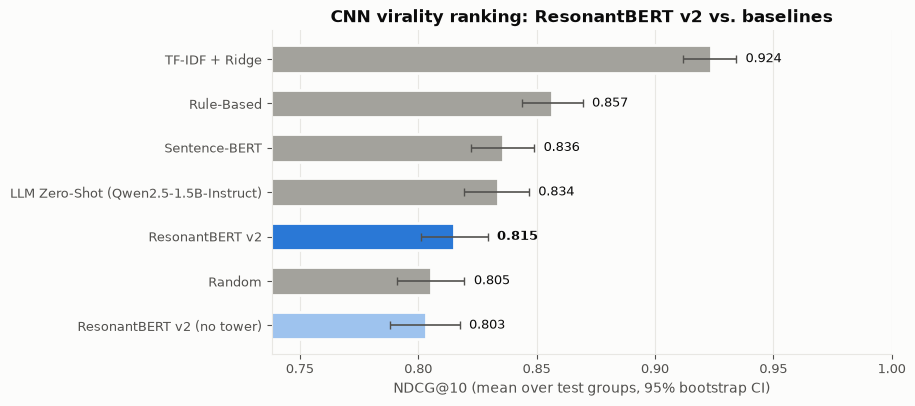

In [20]:
# ---- Figure 1: headline comparison, NDCG@10 with 95% bootstrap CI ----
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(ORDER))
vals = [results[m]["ndcg@10"] for m in ORDER]
err = np.array([[results[m]["ndcg@10"] - results[m]["ndcg@10_ci"][0],
                 results[m]["ndcg@10_ci"][1] - results[m]["ndcg@10"]] for m in ORDER]).T
ax.barh(y, vals, height=0.62, color=[color_of(m) for m in ORDER], edgecolor=C_SURF, linewidth=2)
ax.errorbar(vals, y, xerr=err, fmt="none", ecolor=C_INK2, elinewidth=1.2, capsize=3)
for yi, (m, v) in enumerate(zip(ORDER, vals)):
    ax.text(results[m]["ndcg@10_ci"][1] + 0.004, yi, f"{v:.3f}", va="center", fontsize=9,
            color=C_INK, fontweight="bold" if m == OURS else "normal")
ax.set_yticks(y, ORDER); ax.grid(axis="y", visible=False)
lo = min(results[m]["ndcg@10_ci"][0] for m in ORDER)
ax.set_xlim(max(0, lo - 0.05), 1.0)
ax.set_xlabel("NDCG@10 (mean over test groups, 95% bootstrap CI)")
ax.set_title(f"CNN virality ranking: {OURS} vs. baselines")
save(fig, "fig1_ndcg10_comparison")

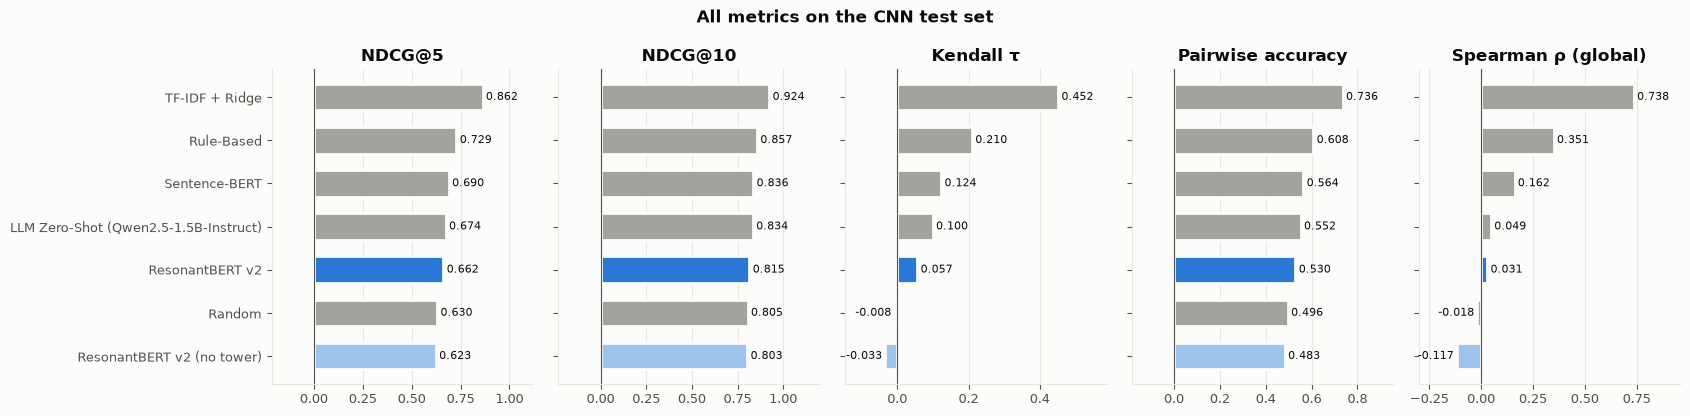

In [21]:
# ---- Figure 2: all metrics, small multiples (one panel per metric, same method order) ----
panels = [("ndcg@5", "NDCG@5"), ("ndcg@10", "NDCG@10"), ("kendall_tau", "Kendall τ"),
          ("pairwise_acc", "Pairwise accuracy"), ("spearman_global", "Spearman ρ (global)")]
fig, axes = plt.subplots(1, len(panels), figsize=(17, 4.2), sharey=True)
for ax, (key, title) in zip(axes, panels):
    vals = [results[m][key] for m in ORDER]
    ax.barh(np.arange(len(ORDER)), vals, height=0.62, color=[color_of(m) for m in ORDER],
            edgecolor=C_SURF, linewidth=2)
    ax.axvline(0, color=C_INK2, linewidth=0.8)
    ax.set_title(title); ax.grid(axis="y", visible=False)
    span = max(abs(v) for v in vals) or 1
    for yi, v in enumerate(vals):
        ax.text(v + (0.02 * span if v >= 0 else -0.02 * span), yi, f"{v:.3f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=C_INK)
    ax.set_xlim(min(0, min(vals)) - 0.25 * span, max(0, max(vals)) + 0.3 * span)
axes[0].set_yticks(np.arange(len(ORDER)), ORDER)
fig.suptitle("All metrics on the CNN test set", fontweight="bold", color=C_INK)
plt.tight_layout()
save(fig, "fig2_all_metrics")

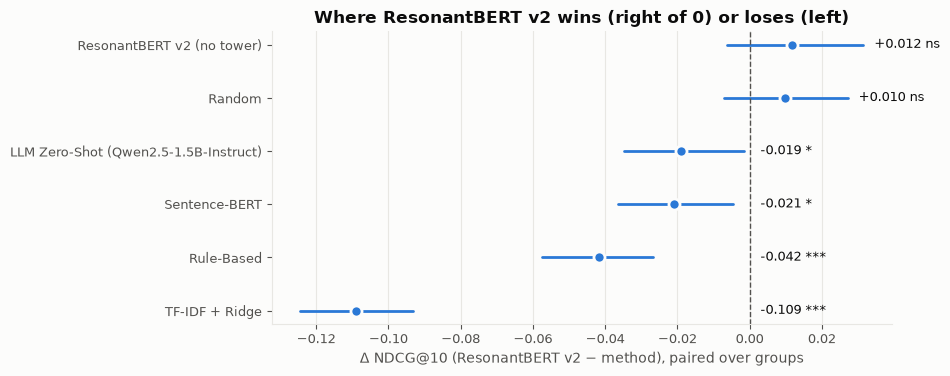

In [22]:
# ---- Figure 3: paired Δ NDCG@10 (ours − other) with 95% CI — forest plot ----
others = sorted(sig, key=lambda m: sig[m]["delta"])
fig, ax = plt.subplots(figsize=(8, 3.8))
for yi, m in enumerate(others):
    s = sig[m]
    ax.plot(s["ci"], [yi, yi], color=C_OURS, linewidth=2, solid_capstyle="round")
    ax.plot(s["delta"], yi, "o", markersize=8, color=C_OURS, markeredgecolor=C_SURF, markeredgewidth=2)
    ax.text(max(s["ci"][1], 0) + 0.003, yi, f"{s['delta']:+.3f} {stars(s['p_t'])}", va="center",
            fontsize=9, color=C_INK)
ax.axvline(0, color=C_INK2, linewidth=1, linestyle="--")
ax.set_yticks(range(len(others)), others); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Δ NDCG@10 ({OURS} − method), paired over groups")
ax.set_title("Where ResonantBERT v2 wins (right of 0) or loses (left)")
save(fig, "fig3_paired_delta_forest")

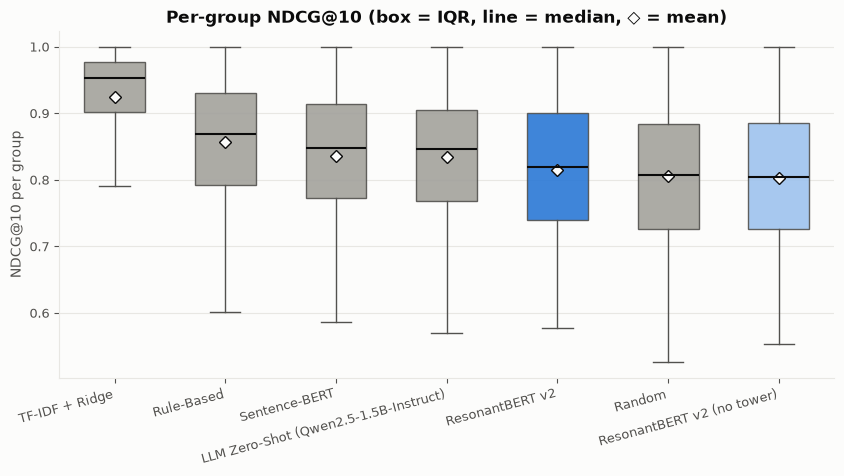

In [23]:
# ---- Figure 4: per-group NDCG@10 distribution ----
order_desc = ORDER[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
data = [[g["ndcg10"] for g in results[m]["per_group"].values()] for m in order_desc]
bp = ax.boxplot(data, tick_labels=order_desc, patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=C_INK, linewidth=1.5),
                whiskerprops=dict(color=C_INK2), capprops=dict(color=C_INK2))
for patch, m in zip(bp["boxes"], order_desc):
    patch.set_facecolor(color_of(m)); patch.set_edgecolor(C_INK2); patch.set_alpha(0.9)
means = [np.mean(d) for d in data]
ax.plot(range(1, len(means) + 1), means, "D", color=C_SURF, markeredgecolor=C_INK, markersize=6, label="mean")
ax.set_ylabel("NDCG@10 per group"); ax.grid(axis="x", visible=False)
ax.set_title("Per-group NDCG@10 (box = IQR, line = median, ◇ = mean)")
plt.xticks(rotation=15, ha="right")
save(fig, "fig4_per_group_distribution")

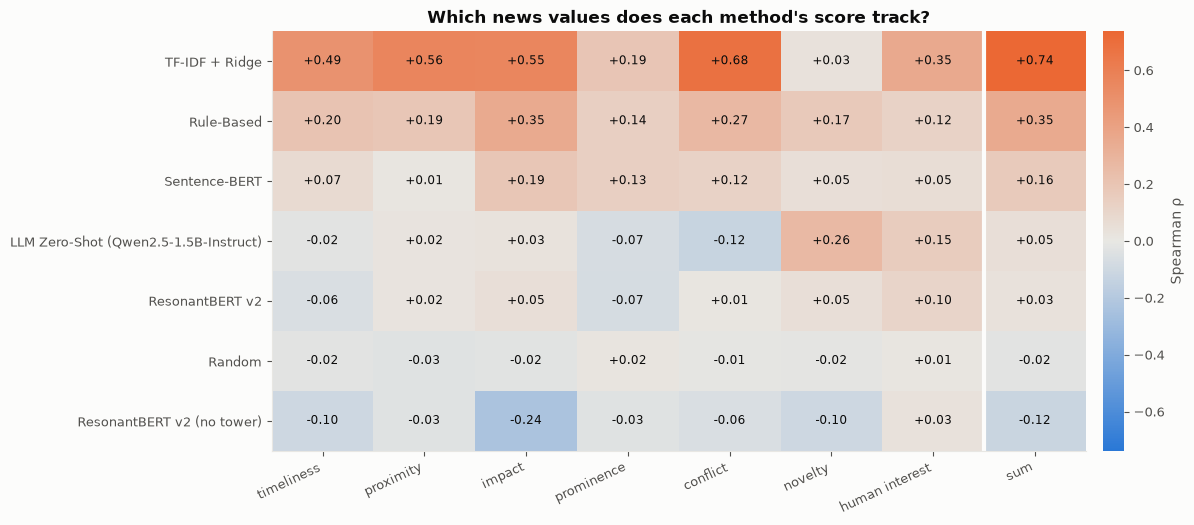

In [24]:
# ---- Figure 5: correlation with each news value (heatmap, diverging around 0) ----
hm = dim_table.loc[ORDER[::-1]]
vmax = max(0.3, np.abs(hm.values).max())
fig, ax = plt.subplots(figsize=(11, 0.55 * len(hm) + 1.6))
im = ax.imshow(hm.values, cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(hm.shape[1]), [c.replace("_", " ") for c in hm.columns], rotation=25, ha="right")
ax.set_yticks(range(hm.shape[0]), hm.index); ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8.5,
                color=C_INK)
ax.axvline(hm.shape[1] - 1.5, color=C_SURF, linewidth=3)   # separate the aggregate target column
cb = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label("Spearman ρ"); cb.outline.set_visible(False)
ax.set_title("Which news values does each method's score track?")
save(fig, "fig5_news_value_correlation")

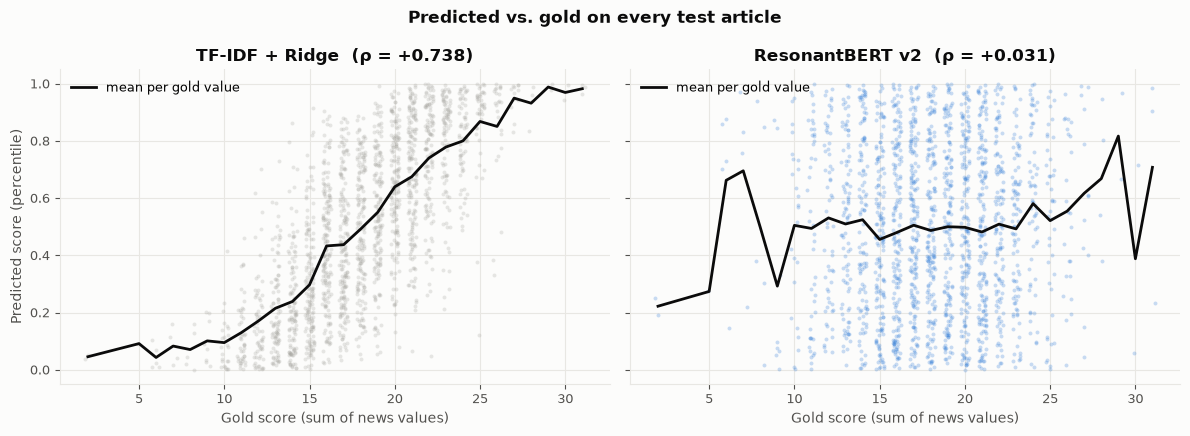

In [25]:
# ---- Figure 6: score vs. gold — ours vs. best baseline ----
best_base = max(BASELINES, key=lambda m: results[m]["ndcg@10"])
gold = test_df["gold"].to_numpy(dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, m in zip(axes, [best_base, OURS]):
    s = test_df[m].to_numpy(dtype=float)
    pct = pd.Series(s).rank(pct=True).to_numpy()          # score percentile → comparable axes
    jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(gold))
    ax.scatter(gold + jitter, pct, s=8, alpha=0.25, color=color_of(m), linewidths=0)
    bins = np.unique(gold)
    ax.plot(bins, [pct[gold == b].mean() for b in bins], color=C_INK, linewidth=2, label="mean per gold value")
    ax.set_title(f"{m}  (ρ = {results[m]['spearman_global']:+.3f})")
    ax.set_xlabel(f"Gold score ({TARGET} of news values)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted score (percentile)")
fig.suptitle("Predicted vs. gold on every test article", fontweight="bold", color=C_INK)
plt.tight_layout()
save(fig, "fig6_score_vs_gold")

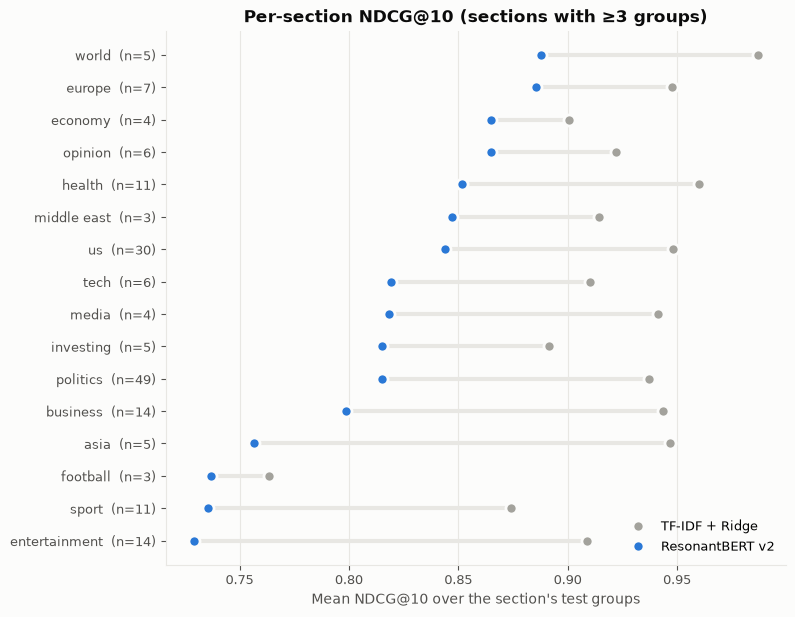

In [26]:
# ---- Figure 7: per-section NDCG@10 — ours vs. best baseline (dumbbell) ----
sec_rows = []
for gi, rows in enumerate(test_groups):
    sec_rows.append({"section": test_df.loc[rows[0], "section"],
                     OURS: results[OURS]["per_group"][gi]["ndcg10"],
                     best_base: results[best_base]["per_group"][gi]["ndcg10"]})
sec = pd.DataFrame(sec_rows).groupby("section").agg(["mean", "count"])
sec = pd.DataFrame({"ours": sec[(OURS, "mean")], "base": sec[(best_base, "mean")],
                    "n": sec[(OURS, "count")]})
sec = sec[sec["n"] >= 3].sort_values("ours")
fig, ax = plt.subplots(figsize=(8, 0.34 * len(sec) + 1.5))
yy = np.arange(len(sec))
ax.hlines(yy, sec["base"], sec["ours"], color=C_GRID, linewidth=3)
ax.plot(sec["base"], yy, "o", markersize=8, color=C_BASE, markeredgecolor=C_SURF, markeredgewidth=2, label=best_base)
ax.plot(sec["ours"], yy, "o", markersize=8, color=C_OURS, markeredgecolor=C_SURF, markeredgewidth=2, label=OURS)
ax.set_yticks(yy, [f"{s}  (n={n})" for s, n in zip(sec.index, sec["n"])]); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean NDCG@10 over the section's test groups")
ax.set_title("Per-section NDCG@10 (sections with ≥3 groups)")
ax.legend(loc="lower right")
save(fig, "fig7_per_section")

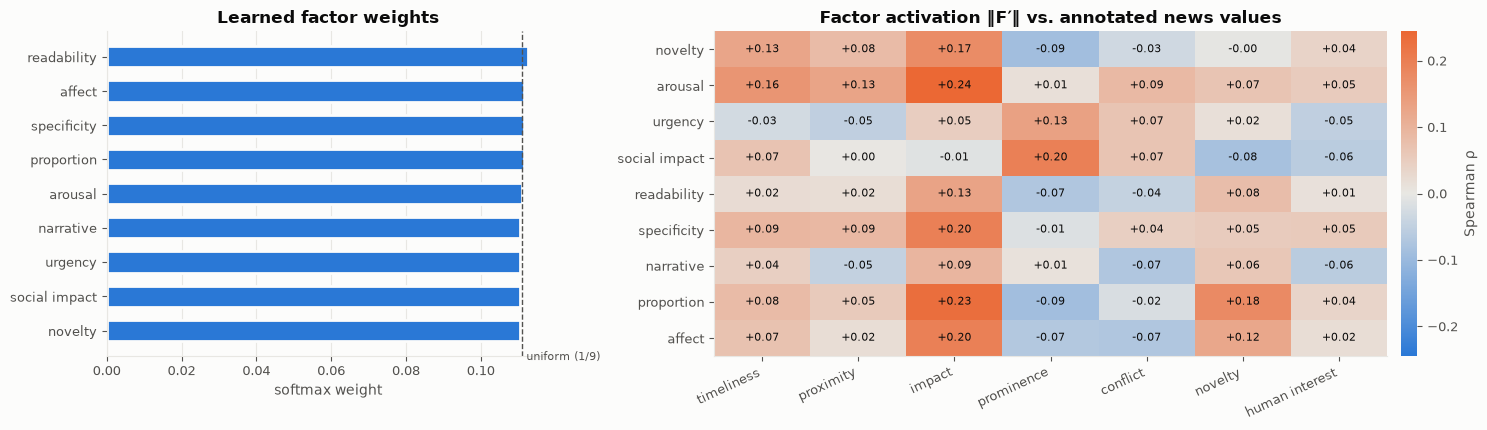

In [27]:
# ---- Figure 8: what the model learned — factor weights + factor/news-value link ----
names = [n.replace("_", " ") for n in ResonantBERTv2.FACTOR_NAMES]
order = np.argsort(FACTOR_WEIGHTS)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})

ax = axes[0]
ax.barh(np.arange(9), FACTOR_WEIGHTS[order], height=0.62, color=C_OURS, edgecolor=C_SURF, linewidth=2)
ax.axvline(1 / 9, color=C_INK2, linestyle="--", linewidth=1)
ax.text(1 / 9, -0.6, " uniform (1/9)", color=C_INK2, fontsize=8, va="top")
ax.set_yticks(np.arange(9), [names[i] for i in order]); ax.grid(axis="y", visible=False)
ax.set_xlabel("softmax weight"); ax.set_title("Learned factor weights")

# Spearman between each factor's activation (‖F'‖) and each annotated news value
fn = model_out["factor_norms"]
link = np.array([[spearmanr(fn[:, i], test_df[v]).correlation for v in NEWS_VALUES] for i in range(9)])
ax = axes[1]
vmax = max(0.2, np.nanmax(np.abs(link)))
im = ax.imshow(link, cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(NEWS_VALUES)), [v.replace("_", " ") for v in NEWS_VALUES], rotation=25, ha="right")
ax.set_yticks(range(9), names); ax.grid(False)
for i in range(9):
    for j in range(len(NEWS_VALUES)):
        ax.text(j, i, f"{link[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color=C_INK)
cb = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.set_label("Spearman ρ"); cb.outline.set_visible(False)
ax.set_title("Factor activation ‖F′‖ vs. annotated news values")
plt.tight_layout()
save(fig, "fig8_factor_analysis")

In [28]:
# ============================================================
# EXPORT: LaTeX tables, JSON, per-article scores
# ============================================================
esc = lambda s: s.replace("_", "\\_").replace("&", "\\&")
best_other = {k: max(results[m][k] for m in METHODS if m != OURS)
              for k in ["ndcg@5", "ndcg@10", "kendall_tau", "pairwise_acc", "spearman_global"]}

latex  = "\\begin{table}[t]\n\\centering\n\\small\n\\begin{tabular}{lccccc}\n\\toprule\n"
latex += ("\\textbf{Model} & \\textbf{NDCG@5} & \\textbf{NDCG@10} & \\textbf{Kendall $\\tau$} & "
          "\\textbf{Pair. Acc.} & \\textbf{Spearman $\\rho$} \\\\\n\\midrule\n")
for m in sorted(METHODS, key=lambda m: -results[m]["ndcg@10"]):
    r = results[m]
    cell = lambda k, fmt="{:.3f}": ("\\textbf{" + fmt.format(r[k]) + "}"
                                    if r[k] >= max(best_other[k], results[OURS][k]) else fmt.format(r[k]))
    mark = f"$^{{{stars(sig[m]['p_t'])}}}$" if m in sig and stars(sig[m]['p_t']) != "ns" else ""
    name = f"\\textbf{{{esc(m)}}}" if m == OURS else esc(m) + mark
    latex += (f"{name} & {cell('ndcg@5')} & {cell('ndcg@10')} & {cell('kendall_tau')} & "
              f"{cell('pairwise_acc')} & {cell('spearman_global')} \\\\\n")
latex += "\\bottomrule\n\\end{tabular}\n"
latex += (f"\\caption{{Zero-shot virality ranking on the CNN test split ({len(test_groups)} groups, "
          f"{len(test_df)} articles; target: {TARGET.replace('_', ' ')} of 7 news values). "
          f"Stars: paired t-test on per-group NDCG@10 vs.\\ {esc(OURS)} "
          f"($^{{*}}p<.05$, $^{{**}}p<.01$, $^{{***}}p<.001$).}}\n")
latex += "\\label{tab:cnn_main}\n\\end{table}"
with open(os.path.join(OUTPUT_DIR, "table_cnn_main.tex"), "w", encoding="utf-8") as f:
    f.write(latex)

export = {m: {k: (v.tolist() if isinstance(v, np.ndarray) else (float(v) if isinstance(v, (np.floating, float)) else v))
              for k, v in results[m].items() if k not in ("per_group", "scores")}
          for m in METHODS}
export["_significance_vs_" + OURS] = {m: {"delta_ndcg10": float(s["delta"]), "ci95": s["ci"].tolist(),
                                          "p_ttest": float(s["p_t"]), "p_wilcoxon": float(s["p_w"]),
                                          "cohens_d": float(s["d"])} for m, s in sig.items()}
export["_factor_weights"] = dict(zip(ResonantBERTv2.FACTOR_NAMES, FACTOR_WEIGHTS.round(5).tolist()))
with open(os.path.join(OUTPUT_DIR, "results_cnn_all.json"), "w", encoding="utf-8") as f:
    json.dump(export, f, indent=2, default=float)

out_scores = test_df.drop(columns=["headline", "body"]).copy()
out_scores["resonant_risk"] = model_out["risk"]
out_scores.to_csv(os.path.join(OUTPUT_DIR, "test_scores_cnn_all.csv"), index=False)

print("EVALUATION COMPLETE")
print(f"Tables/JSON/CSV: {OUTPUT_DIR}")
print(f"Figures:         {FIG_DIR}")
print(f"  {sorted(os.listdir(FIG_DIR))}")
b = max(BASELINES, key=lambda m: results[m]['ndcg@10'])
print(f"\n{OURS}: NDCG@10 = {results[OURS]['ndcg@10']:.4f} | best baseline {b}: {results[b]['ndcg@10']:.4f} "
      f"| Δ = {sig[b]['delta']:+.4f} (p = {sig[b]['p_t']:.2e})")

EVALUATION COMPLETE
Tables/JSON/CSV: c:\Code\05_nlp\ResonantBERT-ResonantRANK\eval_results\cnn_sota
Figures:         c:\Code\05_nlp\ResonantBERT-ResonantRANK\eval_results\cnn_sota\figures
  ['fig1_ndcg10_comparison.pdf', 'fig1_ndcg10_comparison.png', 'fig2_all_metrics.pdf', 'fig2_all_metrics.png', 'fig3_paired_delta_forest.pdf', 'fig3_paired_delta_forest.png', 'fig4_per_group_distribution.pdf', 'fig4_per_group_distribution.png', 'fig5_news_value_correlation.pdf', 'fig5_news_value_correlation.png', 'fig6_score_vs_gold.pdf', 'fig6_score_vs_gold.png', 'fig7_per_section.pdf', 'fig7_per_section.png', 'fig8_factor_analysis.pdf', 'fig8_factor_analysis.png']

ResonantBERT v2: NDCG@10 = 0.8150 | best baseline TF-IDF + Ridge: 0.9239 | Δ = -0.1089 (p = 8.81e-30)
